<table style="border:none;width:100%;table-layout:fixed"><tr style="border:none">
<td style="border:none;text-align:left;vertical-align:middle">
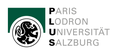</td>
<td style="border:none;text-align:center;vertical-align:middle">
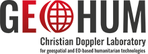</td>
<td style="border:none;text-align:right;vertical-align:middle">
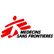</td>
</tr></table>

---

# High-Resolution Urban Heat Mapping - Tondo, Manila
## 01b · Pipeline, step by step

**Christian Doppler Laboratory GEOHUM** - geospatial and EO-based humanitarian technologies
Department of Geoinformatics (Z_GIS), Paris Lodron University of Salzburg · in partnership with **Médecins Sans Frontières**

---

The same processing as `01_pipeline`, with each stage exposed so intermediates can be inspected or varied. Use this when developing or debugging; use `01_pipeline` for production runs.

## Setup

In [ ]:
# Edits to lstpipe/*.py are picked up without restarting the kernel
%load_ext autoreload
%autoreload 2

import sys
from pathlib import Path

# lstpipe lives beside this notebook or one level up
for _c in (Path.cwd(), Path.cwd().parent):
    if (_c / "lstpipe").is_dir():
        sys.path.insert(0, str(_c))
        break

import lstpipe
from lstpipe import Config
print("lstpipe", lstpipe.__version__)

from lstpipe import acquire, covariates, harvest, model, products, viz

MODE = "Day"
cfg = Config.manila(mode=MODE)
print(cfg.summary())
print("outputs ->", cfg.base_dir)

## Authentication

ECOSTRESS is distributed through NASA Earthdata. Searching the catalogue is open, but streaming and downloading files require credentials, so a missing login surfaces late - the search succeeds and the first file access fails.

`persist=True` writes the credentials to `~/.netrc`, so later sessions authenticate silently. The pipeline also calls this itself if you skip the cell.

In [ ]:
import earthaccess

auth = earthaccess.login(persist=True)
print("Earthdata login:", "active" if auth and auth.authenticated else "FAILED")

## 1 · Acquisition

Granules are screened **over HTTPS before download** - each candidate's valid-pixel fraction is measured remotely and only those above threshold are retrieved. Downloads retry with backoff and skip a granule that still fails, rather than losing the run to one transient server error.

*Night requests two windows* (evening and pre-dawn) because the hour test cannot wrap midnight.

In [ ]:
scenes = acquire.screen_and_download(cfg)

## 2 · Reference grids and static layers

The shared spatial frame, built from the study area rather than any granule footprint, so a partially covering date cannot shrink the output. Elevation and land cover are loaded once onto both grids.

In [ ]:
grids = covariates.build_grids(cfg)

## 3 · Per-scene cleaning and harvest

Each overpass is cleaned (`preprocess.prepare_scene`) and paired with **its own** Sentinel-2 predictors.

**Cleaning, in order:** QC-flagged stripe pixels (QC bits 2-3) and a 2-pixel halo removed; clouds and cloud holes buffered by 2 pixels; residual detector lines corrected along the measured scan direction; undetected cloud removed as cold outliers and below `lst_min_c`; shoreline pixels kept for mapping but excluded from training. Nothing is gap-filled. Each overpass is graded A/B/C; C is rejected and logged with its reason.

**Sentinel-2:** no scene is discarded for its cloud percentage. Clouds are masked pixel by pixel with the Scene Classification Layer, the median of clear looks within ±15 days is used, and pixels still cloudy are filled from ±30 then ±60 days. All temperatures are in °C.

In [ ]:
h = harvest.collect(cfg, scenes, grids)

## 4 · Training

**One Random Forest per overpass**, trained on that overpass's own clean 70 m pixels, predicting **absolute land surface temperature in °C**. No anomaly target. This is the NASA ARSET design: each scene's model learns its own level and its own temperature-reflectance relationship, then is applied to the same scene's 10 m Sentinel-2 predictors.

Accuracy is measured on ~1 km **spatial blocks** held out within each scene, not on random pixels, so the model is never scored on near-copies of its training data. Quote per-scene MAE / RMSE in °C and the median per-scene R².

In [ ]:
fit = model.train(cfg, h)
model.save(cfg, fit)

## 5 · Per-overpass maps

The scene's model supplies the 10 m pattern and level; the residual against the scene's clean 70 m observation is added back, so each 10 m block averages to what ECOSTRESS observed (median closure error < 0.01 °C). Pixels ECOSTRESS did not observe stay empty, and the map is cut at the 10 m WorldCover shoreline.

In [ ]:
inventory = products.per_scene_maps(cfg, fit, h, grids)

## 6 · Composites

Planner layers, obtained by averaging the per-scene maps - not by training a second model on blended input, which was tested earlier in the project and failed.

In [ ]:
comp = products.composites(cfg)
viz.planner_products(cfg, comp)
viz.contact_sheet(cfg, only_good=False)